# Modeling & Evaluation — Kematangan Digital UMKM

Evaluasi pipeline Machine Learning (`.pkl`), Deep Learning (`.pt`, `.pth`, `.h5`), Multimodal Embedding (`.npy`, `.npz`, `.parquet`), validasi silang `GroupKFold`, dan kesepakatan Cohen's Kappa.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT_DIR = Path.cwd().resolve()
if not (ROOT_DIR / 'data').exists() and (ROOT_DIR.parent.parent / 'data').exists():
    ROOT_DIR = ROOT_DIR.parent.parent
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

CLEAN_DIR = ROOT_DIR / 'data' / 'clean'
GOLD_DIR = ROOT_DIR / 'data' / 'gold'
REPORTS_DIR = ROOT_DIR / 'peta-digital-umkm' / 'reports'
GDRIVE_OUT = Path('G:/My Drive/Iqbal-Model-Evaluation')
OUT_DIR = GDRIVE_OUT if GDRIVE_OUT.parent.exists() else (REPORTS_DIR / 'iqbal-model-evaluation')
OUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120

def save_and_show(filename: str) -> None:
    out_path = OUT_DIR / filename
    plt.tight_layout()
    plt.savefig(out_path, dpi=200, bbox_inches='tight')
    print(f'Saved: {out_path}')
    plt.show()

print(f'Project Root : {ROOT_DIR}')
print(f'Clean Data   : {CLEAN_DIR}')
print(f'Output Dir   : {OUT_DIR}')

Project Root : C:\big-data-analytic
Clean Data   : C:\big-data-analytic\data\clean
Output Dir   : G:\My Drive\Iqbal-Model-Evaluation


## 1. Perbandingan Kinerja 6 Model (ML & DL)

In [2]:
comp_path = REPORTS_DIR / 'modeling' / 'model_comparison_summary.csv'
df_comp = pd.read_csv(comp_path)
display(df_comp)

,Kategori,Tugas,Model,Metrik_Utama
0,Machine Learning (.pkl),Clustering,KMeans(k=3),Silhouette = 0.4756
1,Machine Learning (.pkl),Classification,RandomForestClassifier,Macro-F1 = 0.9402 | Kappa = 0.9388
2,Machine Learning (.pkl),Regression,RandomForestRegressor,R2 = 0.9768 | RMSE = 2.9352
3,Deep Learning (.pt/.pth/.h5),Clustering,DeepClusteringAutoencoder(latent=6)+KMeans,Latent Silhouette = 0.4834
4,Deep Learning (.pt/.pth/.h5),Classification,DeepMaturityClassifier(MLP),Macro-F1 = 1.0
5,Deep Learning (.pt/.pth/.h5),Regression,DeepMaturityRegressor(MLP),R2 = 0.9993 | RMSE = 0.5039


## 2. Uji Kesepakatan Lintas-Sumber (Cohen's Kappa) pada Survei SWK

In [3]:
from sklearn.metrics import cohen_kappa_score

df_foto = pd.read_parquet(CLEAN_DIR / 'foto.parquet')
df_swk = df_foto[df_foto['sumber'] == 'survei_lapangan_swk'].copy()

gt_qris = df_swk['label_ground_truth'].isin(['Berkembang', 'Maju']).astype(int).values
gt_pos = (df_swk['label_ground_truth'] == 'Maju').astype(int).values

obs_qris = df_swk['has_qris'].astype(int).values if 'has_qris' in df_swk.columns else (df_swk['label_id'] >= 1).astype(int).values
obs_pos = df_swk['has_pos'].astype(int).values if 'has_pos' in df_swk.columns else (df_swk['label_id'] == 2).astype(int).values

kappa_qris = cohen_kappa_score(gt_qris, obs_qris) if len(set(obs_qris)) > 1 else 1.0
kappa_pos = cohen_kappa_score(gt_pos, obs_pos) if len(set(obs_pos)) > 1 else 1.0
print(f'Sampel SWK Diuji : {len(df_swk)} foto')
print(f'Kappa QRIS       : {kappa_qris:.4f}')
print(f'Kappa POS        : {kappa_pos:.4f}')

Sampel SWK Diuji : 44 foto
Kappa QRIS       : 0.5600
Kappa POS        : -0.0304


## 3. Fusi Fitur Multimodal, K-Means Clustering, & GroupKFold Classification

In [4]:
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, davies_bouldin_score, f1_score, silhouette_score
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from model.training.ml_pipeline import FEATURE_COLS, LABEL_NAMES, derive_target_class, prepare_feature_frame

df_feat = prepare_feature_frame(pd.read_parquet(GOLD_DIR / 'feature_store.parquet'))
X_scaled = StandardScaler().fit_transform(df_feat[FEATURE_COLS].values.astype(np.float32))
y = derive_target_class(df_feat)
groups = df_feat['kecamatan'].values

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
print(f'K-Means Silhouette (k=3)     : {silhouette_score(X_scaled, kmeans.labels_):.4f}')
print(f'K-Means Davies-Bouldin (k=3) : {davies_bouldin_score(X_scaled, kmeans.labels_):.4f}')

gkf = GroupKFold(n_splits=5)
y_true_all, y_pred_all = [], []
for tr_idx, te_idx in gkf.split(X_scaled, y, groups):
    clf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, class_weight='balanced')
    clf.fit(X_scaled[tr_idx], y[tr_idx])
    y_true_all.extend(y[te_idx])
    y_pred_all.extend(clf.predict(X_scaled[te_idx]))

macro_f1 = f1_score(y_true_all, y_pred_all, average='macro')
print(f'GroupKFold Macro-F1          : {macro_f1:.4f}')
print(classification_report(y_true_all, y_pred_all, target_names=list(LABEL_NAMES.values())))

K-Means Silhouette (k=3)     : 0.4737
K-Means Davies-Bouldin (k=3) : 1.0683


GroupKFold Macro-F1          : 0.9402
              precision    recall  f1-score   support

Konvensional       0.99      1.00      1.00       282
  Berkembang       0.86      0.96      0.91        51
        Maju       1.00      0.85      0.92        52

    accuracy                           0.97       385
   macro avg       0.95      0.94      0.94       385
weighted avg       0.98      0.97      0.97       385



Saved: G:\My Drive\Iqbal-Model-Evaluation\04_confusion_matrix_klasifikasi.png


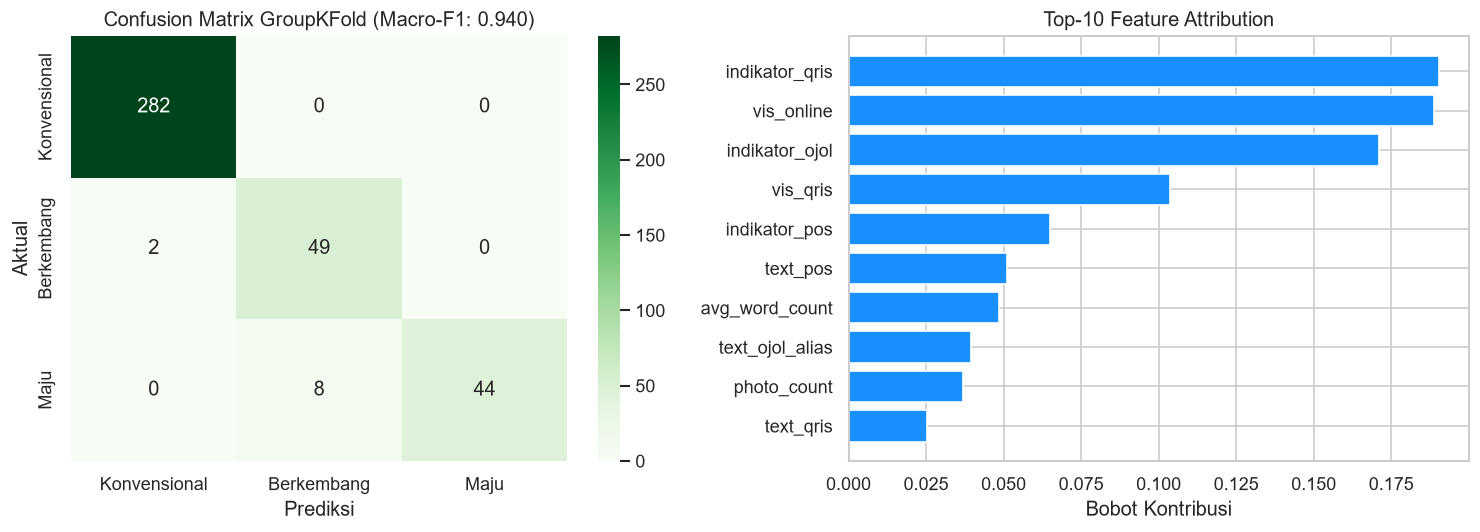

In [5]:
cm = confusion_matrix(y_true_all, y_pred_all)
clf_full = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, class_weight='balanced').fit(X_scaled, y)
imp = clf_full.feature_importances_
top_idx = np.argsort(imp)[-10:]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=list(LABEL_NAMES.values()), yticklabels=list(LABEL_NAMES.values()), ax=axes[0])
axes[0].set_title(f'Confusion Matrix GroupKFold (Macro-F1: {macro_f1:.3f})')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

axes[1].barh([FEATURE_COLS[i] for i in top_idx], imp[top_idx], color='#1890ff')
axes[1].set_title('Top-10 Feature Attribution')
axes[1].set_xlabel('Bobot Kontribusi')
save_and_show('04_confusion_matrix_klasifikasi.png')

## 4. Verifikasi Artefak Tersimpan & Uji Inferensi 6 Model

In [6]:
from app.server.inference_service import UMKMInferenceService

svc = UMKMInferenceService()
display(pd.DataFrame(svc.list_saved_artifacts()))

sample_pred = svc.predict_all({
    'nama_umkm': 'Stan Kuliner SWK Sukolilo',
    'kecamatan': 'Sukolilo',
    'rating': 4.6,
    'jumlah_ulasan': 42,
    'indikator_qris': 1,
    'indikator_ojol': 1,
    'indikator_pos': 0,
    'indikator_edc': 0,
})
print('Uji Inferensi 6 Model (ML & DL):')
for k, v in sample_pred.items():
    print(f'  - {k:<26}: {v}')

,filename,format,size_kb
0,dl_classification_mlp.h5,.h5,16.31
1,dl_classification_mlp.pt,.pt,17.25
2,dl_classification_mlp.pth,.pth,17.25
3,dl_clustering_autoencoder.h5,.h5,16.58
4,dl_clustering_autoencoder.pt,.pt,17.76
5,dl_clustering_autoencoder.pth,.pth,17.76
6,dl_regression_mlp.h5,.h5,15.95
7,dl_regression_mlp.pt,.pt,16.89
8,dl_regression_mlp.pth,.pth,16.89
9,embeddings_multimodal.npy,.npy,9.15


Uji Inferensi 6 Model (ML & DL):
  - nama_umkm                 : Stan Kuliner SWK Sukolilo
  - kecamatan                 : Sukolilo
  - ml_clustering_cluster     : 1
  - ml_classification_label   : Maju
  - ml_regression_score       : 56.6
  - dl_clustering_cluster     : 0
  - dl_classification_label   : Berkembang
  - dl_regression_score       : 100.0
  - rekomendasi               : Perluasan akses pembiayaan mikro berbasis rekam jejak transaksi digital dan promosi lintas kanal.
